# Car Price Prediction Using Machine Learning

## Introduction

This project focuses on predicting the prices of used cars using Machine Learning.

The dataset contains information about used cars, including features such as car brand, manufacturing year, kilometers driven, fuel type, seller type, transmission type, ownership information, and other relevant attributes.

The objective is to build a regression model that learns the relationship between these car-related features and their selling prices.

The project covers the following steps:

- Loading the dataset directly from Kaggle using KaggleHub
- Exploring and understanding the dataset
- Handling missing values and duplicate records
- Performing feature engineering
- Converting categorical variables into numerical form
- Splitting the data into training and testing sets
- Training a regression model
- Evaluating model performance using MAE, RMSE, and R²
- Visualizing actual versus predicted prices
- Using the trained model to predict car prices

This demonstrates a real-world Machine Learning application where historical vehicle data can be used to estimate the market value of used cars.

# Loading important libraries for the task

In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import kagglehub

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Loading dataset

In [4]:
path = kagglehub.dataset_download("vijayaadithyanvg/car-price-predictionused-cars")

print("Path to dataset files:", path)
print(os.listdir(path))

100%|██████████| 3.76k/3.76k [00:00<00:00, 5.57MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/vijayaadithyanvg/car-price-predictionused-cars/versions/1
['car data.csv']


In [5]:
csv_files = [file for file in os.listdir(path) if file.endswith(".csv")]

print("CSV files:", csv_files)

CSV files: ['car data.csv']


In [7]:
df = pd.read_csv(os.path.join(path, csv_files[0]))


# Overview of dataset

In [8]:
df.sample(10)

,Car_Name,Year,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner
269,city,2015,6.70,10.00,18828,Petrol,Dealer,Manual,0
244,verna,2013,5.95,9.40,49000,Diesel,Dealer,Manual,0
26,swift,2013,4.15,5.87,55138,Petrol,Dealer,Manual,0
217,eon,2016,3.15,4.43,15000,Petrol,Dealer,Manual,0
105,KTM RC390,2015,1.35,2.37,21700,Petrol,Individual,Manual,0
203,i10,2011,2.95,4.60,53460,Petrol,Dealer,Manual,0
152,Bajaj Pulsar NS 200,2012,0.50,0.99,13000,Petrol,Individual,Manual,0
300,brio,2016,5.30,5.90,5464,Petrol,Dealer,Manual,0
125,Royal Enfield Classic 500,2009,0.90,1.75,40000,Petrol,Individual,Manual,0
207,grand i10,2015,5.15,5.70,34797,Petrol,Dealer,Automatic,0


# data Exploration

In [9]:
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

Shape: (301, 9)

Columns:
['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Driven_kms', 'Fuel_Type', 'Selling_type', 'Transmission', 'Owner']


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    object 
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Driven_kms     301 non-null    int64  
 5   Fuel_Type      301 non-null    object 
 6   Selling_type   301 non-null    object 
 7   Transmission   301 non-null    object 
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 21.3+ KB


In [11]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Car_Name,301,98,city,26,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Year,301.0,NaN,NaN,NaN,2013.627907,2.891554,2003.0,2012.0,2014.0,2016.0,2018.0
Selling_Price,301.0,NaN,NaN,NaN,4.661296,5.082812,0.1,0.9,3.6,6.0,35.0
Present_Price,301.0,NaN,NaN,NaN,7.628472,8.642584,0.32,1.2,6.4,9.9,92.6
Driven_kms,301.0,NaN,NaN,NaN,36947.20598,38886.883882,500.0,15000.0,32000.0,48767.0,500000.0
Fuel_Type,301,3,Petrol,239,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Selling_type,301,2,Dealer,195,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Transmission,301,2,Manual,261,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Owner,301.0,NaN,NaN,NaN,0.043189,0.247915,0.0,0.0,0.0,0.0,3.0


# Data Cleaning

In [12]:
missing_values = df.isnull().sum().sort_values(ascending=False)

missing_values[missing_values > 0]

,0


In [13]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 2


In [14]:
df = df.drop_duplicates().reset_index(drop=True)

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (299, 9)


In [15]:
print(df.columns.tolist())

['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Driven_kms', 'Fuel_Type', 'Selling_type', 'Transmission', 'Owner']


In [17]:
target = "Selling_Price"

print(df[target].describe())

count    299.000000
mean       4.589632
std        4.984240
min        0.100000
25%        0.850000
50%        3.510000
75%        6.000000
max       35.000000
Name: Selling_Price, dtype: float64


# visualize Distribution

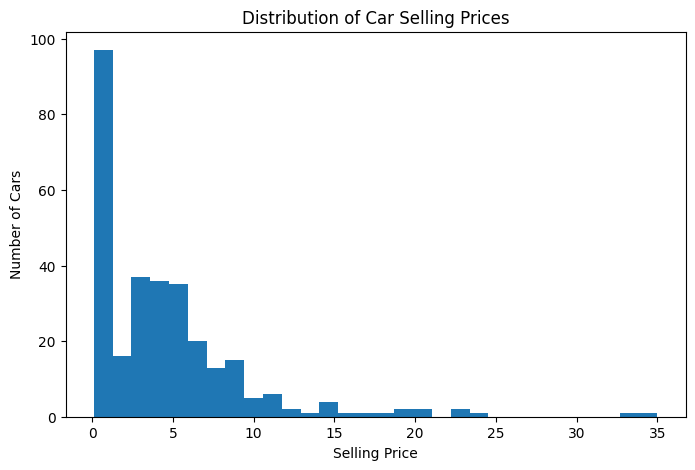

In [18]:
plt.figure(figsize=(8, 5))
plt.hist(df[target], bins=30)
plt.xlabel("Selling Price")
plt.ylabel("Number of Cars")
plt.title("Distribution of Car Selling Prices")
plt.show()

# feature Engineering

In [19]:
df.columns

Index(['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Driven_kms',
       'Fuel_Type', 'Selling_type', 'Transmission', 'Owner'],
      dtype='object')

In [22]:
df["Car_Age"] = 2026 - df["Year"]

In [23]:
df["Car_Age"] = 2026 - df["Year"]

In [24]:
df[["Year", "Car_Age", "Present_Price", "Driven_kms", "Selling_Price"]].head()

,Year,Car_Age,Present_Price,Driven_kms,Selling_Price
0,2014,12,5.59,27000,3.35
1,2013,13,9.54,43000,4.75
2,2017,9,9.85,6900,7.25
3,2011,15,4.15,5200,2.85
4,2014,12,6.87,42450,4.60


In [25]:
X = df.drop(columns=["Selling_Price", "Car_Name"])
y = df["Selling_Price"]

In [26]:
X = df.drop(columns=["Selling_Price", "Car_Name"])
y = df["Selling_Price"]

In [27]:
numeric_features = X.select_dtypes(include=["int64", "float64", "int32", "float32"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Numerical features: ['Year', 'Present_Price', 'Driven_kms', 'Owner', 'Car_Age']
Categorical features: ['Fuel_Type', 'Selling_type', 'Transmission']


# Preprocessing

In [28]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

# Building Model

In [29]:
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ]
)

pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Year', 'Present_Price',
                                                   'Driven_kms', 'Owner',
                                                   'Car_Age']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Fuel_Type', 'Selling_type',
                                                   'Transmission'])])),
                ('model',
                 RandomForestRegressor(n_estimators=200, n_jobs=-1,
                                       random_state=42))])

# model Evaluation

In [30]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

y_pred = pipeline.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error:", mae)
print("Root Mean Squared Error:", rmse)
print("R² Score:", r2)

Mean Absolute Error: 1.5487249999999995
Root Mean Squared Error: 3.7730960593721976
R² Score: 0.4476347716287453


# Actual Price bs Predicted Price

In [31]:
results = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

results.head(10)

,Actual Price,Predicted Price
0,8.99,9.44700
1,8.35,8.27600
2,0.45,0.44065
3,7.45,6.97450
4,5.25,18.56720
5,5.25,5.29925
6,5.85,6.70645
7,1.15,1.18925
8,9.25,7.88875
9,0.38,0.31135


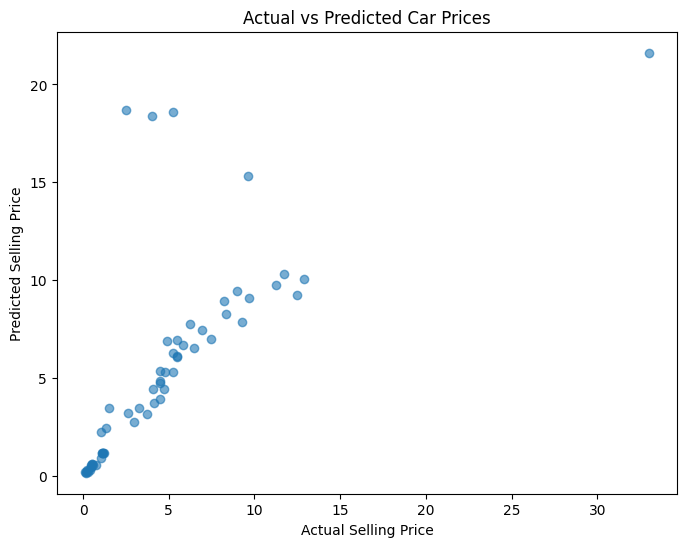

In [32]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.6)

plt.xlabel("Actual Selling Price")
plt.ylabel("Predicted Selling Price")
plt.title("Actual vs Predicted Car Prices")

plt.show()

# Prediction Error Distribution

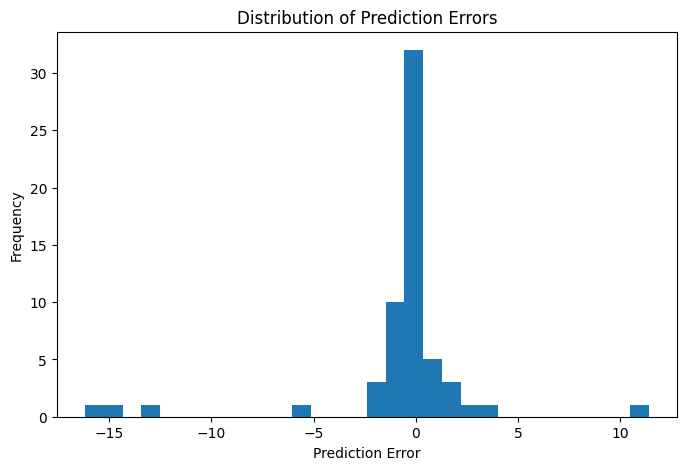

In [33]:
errors = y_test - y_pred

plt.figure(figsize=(8, 5))
plt.hist(errors, bins=30)

plt.xlabel("Prediction Error")
plt.ylabel("Frequency")
plt.title("Distribution of Prediction Errors")

plt.show()

# Feature Importance

In [34]:
feature_names = pipeline.named_steps["preprocessor"].get_feature_names_out()

importances = pipeline.named_steps["model"].feature_importances_

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

feature_importance.head(15)

,Feature,Importance
1,num__Present_Price,0.900468
0,num__Year,0.039887
4,num__Car_Age,0.037495
2,num__Driven_kms,0.011803
10,cat__Transmission_Automatic,0.003203
11,cat__Transmission_Manual,0.003140
9,cat__Selling_type_Individual,0.001377
8,cat__Selling_type_Dealer,0.001075
6,cat__Fuel_Type_Diesel,0.000786
7,cat__Fuel_Type_Petrol,0.000757


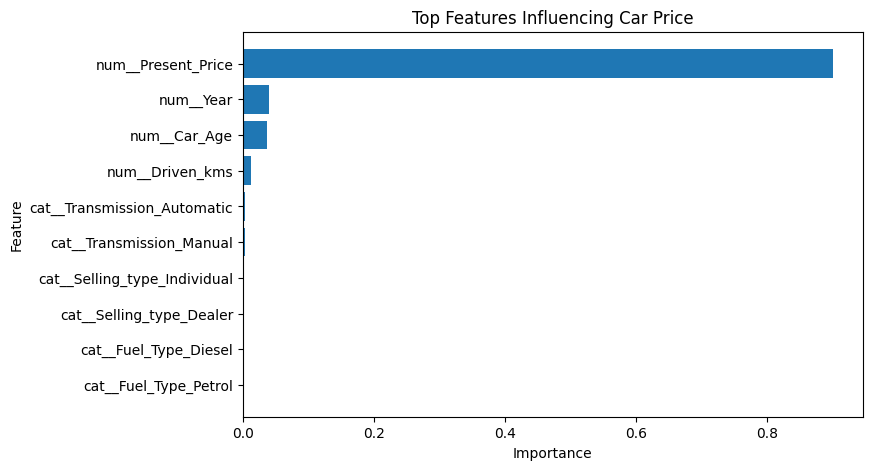

In [36]:
top_features = feature_importance.head(10).sort_values("Importance")

plt.figure(figsize=(8, 5))
plt.barh(top_features["Feature"], top_features["Importance"])

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top Features Influencing Car Price")

plt.show()

# FInal Model Performance

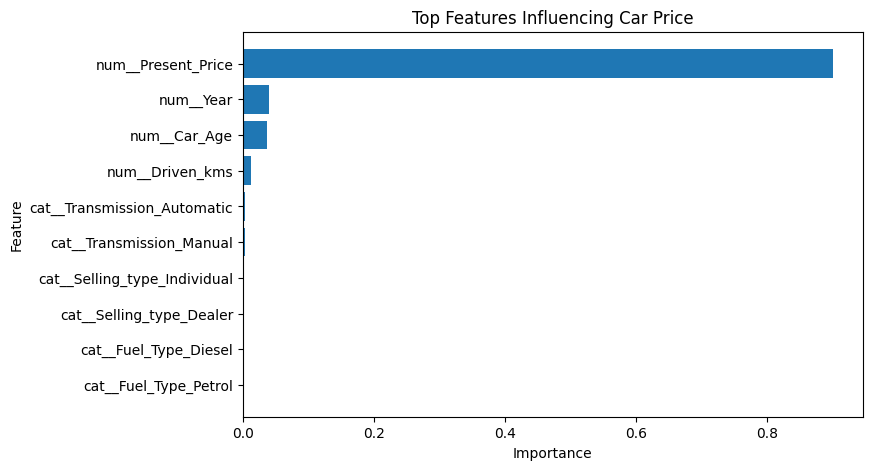

In [37]:
top_features = feature_importance.head(10).sort_values("Importance")

plt.figure(figsize=(8, 5))
plt.barh(top_features["Feature"], top_features["Importance"])

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top Features Influencing Car Price")

plt.show()

# Example Prediction

In [38]:
sample = X_test.iloc[[0]]

predicted_price = pipeline.predict(sample)[0]
actual_price = y_test.iloc[0]

print("Actual Selling Price:", actual_price)
print("Predicted Selling Price:", predicted_price)

Actual Selling Price: 8.99
Predicted Selling Price: 9.44699999999999


## Conclusion

A Random Forest Regression model was developed to predict used-car selling prices using vehicle characteristics such as manufacturing year, present price, kilometers driven, fuel type, selling type, transmission, ownership, and car age.

The dataset was collected directly from Kaggle using KaggleHub and processed using Pandas and Scikit-learn. Missing values were handled using a preprocessing pipeline, categorical variables were encoded using One-Hot Encoding, and numerical features were standardized.

The model achieved a Mean Absolute Error of 1.55, a Root Mean Squared Error of 3.77, and an R² Score of 0.448 on the test dataset.

The model's predictions were further analyzed using actual-versus-predicted plots, prediction error distribution, and feature importance.

The project demonstrates how Machine Learning regression can be applied to estimate used-car prices from historical vehicle data. The model provides a data-driven approach to price estimation, although its performance can be affected by factors not represented in the dataset, such as vehicle condition, location, accident history, maintenance history, and changes in market demand.